<a href="https://colab.research.google.com/github/sunilchoudhary99/PBL-Project-1/blob/main/spotify_song_popularity_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Introduction**



As I am in the initial stages of developing my data science and singer-songwriting careers, I thought it would be appropriate to bring both fields together to inform my analysis and songwriting skills. For this short project, I will be predicting the popularity of songs based purely on song metrics such as key, dancibility, and acousticness. Year, artist, era, and genre will not be included.


**2. Import Packages**

In [ ]:
import numpy as np
import pandas as pd # for working with dataframes
import seaborn as sns # for data visualization

from matplotlib import pyplot as plt # for plotting
%matplotlib inline
sns.set_style("whitegrid")

import warnings # http://blog.johnmuellerbooks.com/2015/11/30/warnings-in-python-and-anaconda/
warnings.filterwarnings("ignore")

**3. Loading and Viewing Dataset**

We load the dataset and look at the overall statistics such as mean, count, and median.

In [ ]:
dataframe = pd.read_csv('../input/SpotifyFeatures.csv')
dataframe.head()

,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
0,Opera,Giuseppe Verdi,"Stiffelio, Act III: Ei fugge! … Lina, pensai c...",7EsKYeHtTc4H4xWiTqSVZA,21,0.986,0.313,490867,0.23100,0.000431,C#,0.0964,-14.287,Major,0.0547,86.001,4/4,0.0886
1,Opera,Giacomo Puccini,Madama Butterfly / Act 1: ... E soffitto e pareti,7MfmRBvqaW0I6UTxXnad8p,18,0.972,0.360,176797,0.20100,0.028000,D#,0.1330,-19.794,Major,0.0581,131.798,4/4,0.3690
2,Opera,Giacomo Puccini,"Turandot / Act 2: Gloria, gloria, o vincitore",7pBo1GDhIysyUMFXiDVoON,10,0.935,0.168,266184,0.47000,0.020400,C,0.3630,-8.415,Major,0.0383,75.126,3/4,0.0696
3,Opera,Giuseppe Verdi,"Rigoletto, Act IV: Venti scudi hai tu detto?",02mvYZX5aKNzdqEo6jF20m,17,0.961,0.250,288573,0.00605,0.000000,D,0.1200,-33.440,Major,0.0480,76.493,4/4,0.0380
4,Opera,Giuseppe Verdi,"Don Carlo / Act 4: ""Ella giammai m'amò!""",03TW0jwGMGhUabAjOpB1T9,19,0.985,0.142,629760,0.05800,0.146000,D,0.0969,-23.625,Major,0.0493,172.935,4/4,0.0382


In [ ]:
dataframe.describe()

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence
count,228159.000000,228159.000000,228159.000000,2.281590e+05,228159.000000,228159.000000,228159.000000,228159.000000,228159.000000,228159.000000,228159.000000
mean,44.209130,0.351200,0.554198,2.366092e+05,0.580967,0.137310,0.214638,-9.354658,0.122442,117.423062,0.444795
std,17.276599,0.351385,0.183949,1.166787e+05,0.260577,0.292447,0.196977,5.940994,0.186264,30.712458,0.255397
min,0.000000,0.000001,0.056900,1.550900e+04,0.000020,0.000000,0.009670,-52.457000,0.022200,30.379000,0.000000
25%,33.000000,0.030900,0.437000,1.862530e+05,0.405000,0.000000,0.097700,-11.287000,0.036800,92.734000,0.232000
50%,47.000000,0.205000,0.570000,2.211730e+05,0.618000,0.000037,0.128000,-7.515000,0.050600,115.347000,0.430000
75%,57.000000,0.689000,0.690000,2.648400e+05,0.793000,0.023400,0.263000,-5.415000,0.109000,138.887000,0.643000
max,100.000000,0.996000,0.987000,5.552917e+06,0.999000,0.999000,1.000000,1.585000,0.967000,239.848000,1.000000


In [ ]:
print(dataframe.keys())

Index(['genre', 'artist_name', 'track_name', 'track_id', 'popularity',
       'acousticness', 'danceability', 'duration_ms', 'energy',
       'instrumentalness', 'key', 'liveness', 'loudness', 'mode',
       'speechiness', 'tempo', 'time_signature', 'valence'],
      dtype='object')


A link to the definitions of these features is shown here: https://developer.spotify.com/documentation/web-api/reference/tracks/get-audio-features/

**4. Cleaning NaN Values**

We check for null values.

In [ ]:
pd.isnull(dataframe).sum()

genre               0
artist_name         0
track_name          0
track_id            0
popularity          0
acousticness        0
danceability        0
duration_ms         0
energy              0
instrumentalness    0
key                 0
liveness            0
loudness            0
mode                0
speechiness         0
tempo               0
time_signature      0
valence             0
dtype: int64

Since there are no null values, we don't have to worry about filling in missing information.

**5. Exploratory Analysis**

We investigate overall trends in the data to get a good idea of which variables correlate with each other as well as other associations.

Text(0.5, 1.0, 'Popularity Distribution')

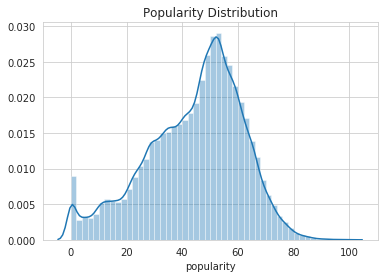

In [ ]:
sns.distplot(dataframe['popularity']).set_title('Popularity Distribution')

In [ ]:
dataframe.corr()

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence
popularity,1.000000,-0.422083,0.294233,-0.041150,0.277652,-0.230042,-0.203147,0.413276,-0.194673,0.114957,0.119224
acousticness,-0.422083,1.000000,-0.379441,0.035410,-0.723150,0.323748,0.086149,-0.698187,0.165105,-0.241385,-0.335430
danceability,0.294233,-0.379441,1.000000,-0.116437,0.338110,-0.360938,-0.034043,0.451336,0.135728,0.018950,0.542405
duration_ms,-0.041150,0.035410,-0.116437,1.000000,-0.058045,0.094618,0.006760,-0.068716,-0.017621,-0.027957,-0.135970
energy,0.277652,-0.723150,0.338110,-0.058045,1.000000,-0.388705,0.182697,0.816640,0.141294,0.228067,0.449463
instrumentalness,-0.230042,0.323748,-0.360938,0.094618,-0.388705,1.000000,-0.131840,-0.517373,-0.173734,-0.108424,-0.301990
liveness,-0.203147,0.086149,-0.034043,0.006760,0.182697,-0.131840,1.000000,0.035792,0.519542,-0.055556,0.018264
loudness,0.413276,-0.698187,0.451336,-0.068716,0.816640,-0.517373,0.035792,1.000000,-0.008912,0.229110,0.407057
speechiness,-0.194673,0.165105,0.135728,-0.017621,0.141294,-0.173734,0.519542,-0.008912,1.000000,-0.085619,0.035007
tempo,0.114957,-0.241385,0.018950,-0.027957,0.228067,-0.108424,-0.055556,0.229110,-0.085619,1.000000,0.120573


Text(0.5, 1.0, 'Popularity Based on Time Signature')

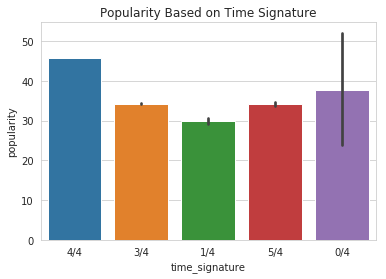

In [ ]:
sns.barplot(x = 'time_signature', y = 'popularity', data = dataframe)
plt.title('Popularity Based on Time Signature')

Text(0.5, 1.0, 'Popularity Based on Key')

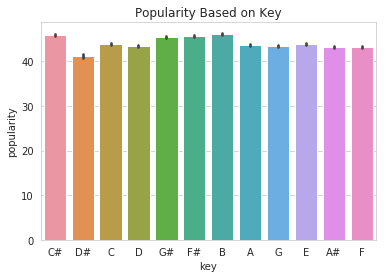

In [ ]:
sns.barplot(x = 'key', y = 'popularity', data = dataframe)
plt.title('Popularity Based on Key')

Text(0.5, 1.0, 'Popularity Based on Mode')

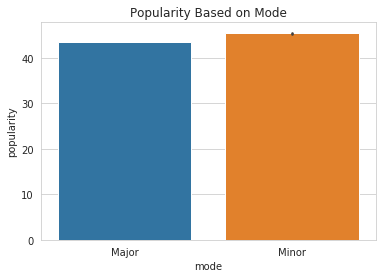

In [ ]:
sns.barplot(x = 'mode', y = 'popularity', data = dataframe)
plt.title('Popularity Based on Mode')

Since key and mode are related (there can be A major or A minor), we combine those two features in another barplot using "hue".

Text(0.5, 1.0, 'Popularity Based on Mode and Key')

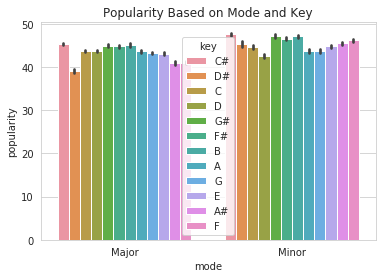

In [ ]:
sns.barplot(x = 'mode', y = 'popularity', hue = 'key', data = dataframe)
plt.title('Popularity Based on Mode and Key')

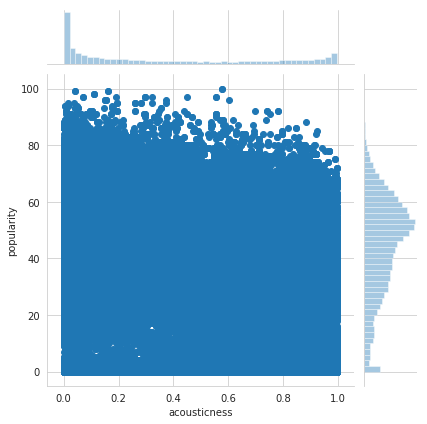

In [ ]:
sns.jointplot(x = 'acousticness', y = 'popularity', data = dataframe)

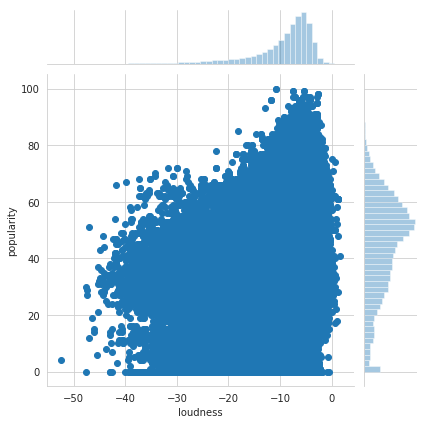

In [ ]:
sns.jointplot(x = 'loudness', y = 'popularity', data = dataframe)

Text(0.5, 1.0, 'Acoustiness for Songs with More than 50 Popularity')

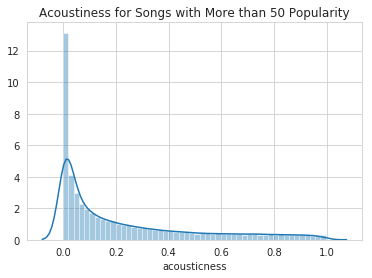

In [ ]:
popular_above_50 = dataframe[dataframe.popularity > 50]
sns.distplot(popular_above_50['acousticness'])
plt.title('Acoustiness for Songs with More than 50 Popularity')

Text(0.5, 1.0, 'Acoustiness for Songs with Less than 50 Popularity')

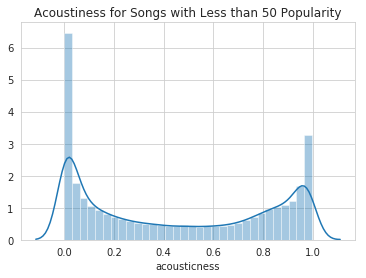

In [ ]:
popular_below_50 = dataframe[dataframe.popularity < 50]
sns.distplot(popular_below_50['acousticness'])
plt.title('Acoustiness for Songs with Less than 50 Popularity')

Text(0.5, 1.0, 'Loudness for Songs with More than 50 Popularity')

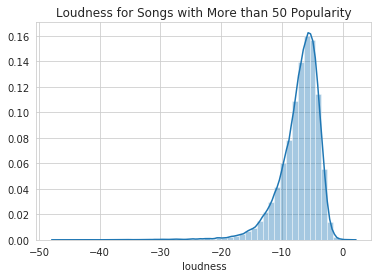

In [ ]:
sns.distplot(popular_above_50['loudness'])
plt.title('Loudness for Songs with More than 50 Popularity')


Text(0.5, 1.0, 'Loudness for Songs with Less than 50 Popularity')

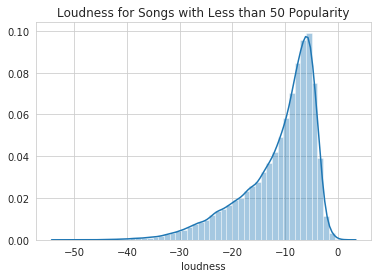

In [ ]:
popular_below_50 = dataframe[dataframe.popularity < 50]
sns.distplot(popular_below_50['loudness'])
plt.title('Loudness for Songs with Less than 50 Popularity')

From this analysis, there loudness" and acousticness features have medium-weak correlations with popularity. Furthermore, the distributions of loudness and acousticness differ for songs with more than 50 popularity vs. songs with less than 50 popularity. We plot a summary of all relationships between the features.

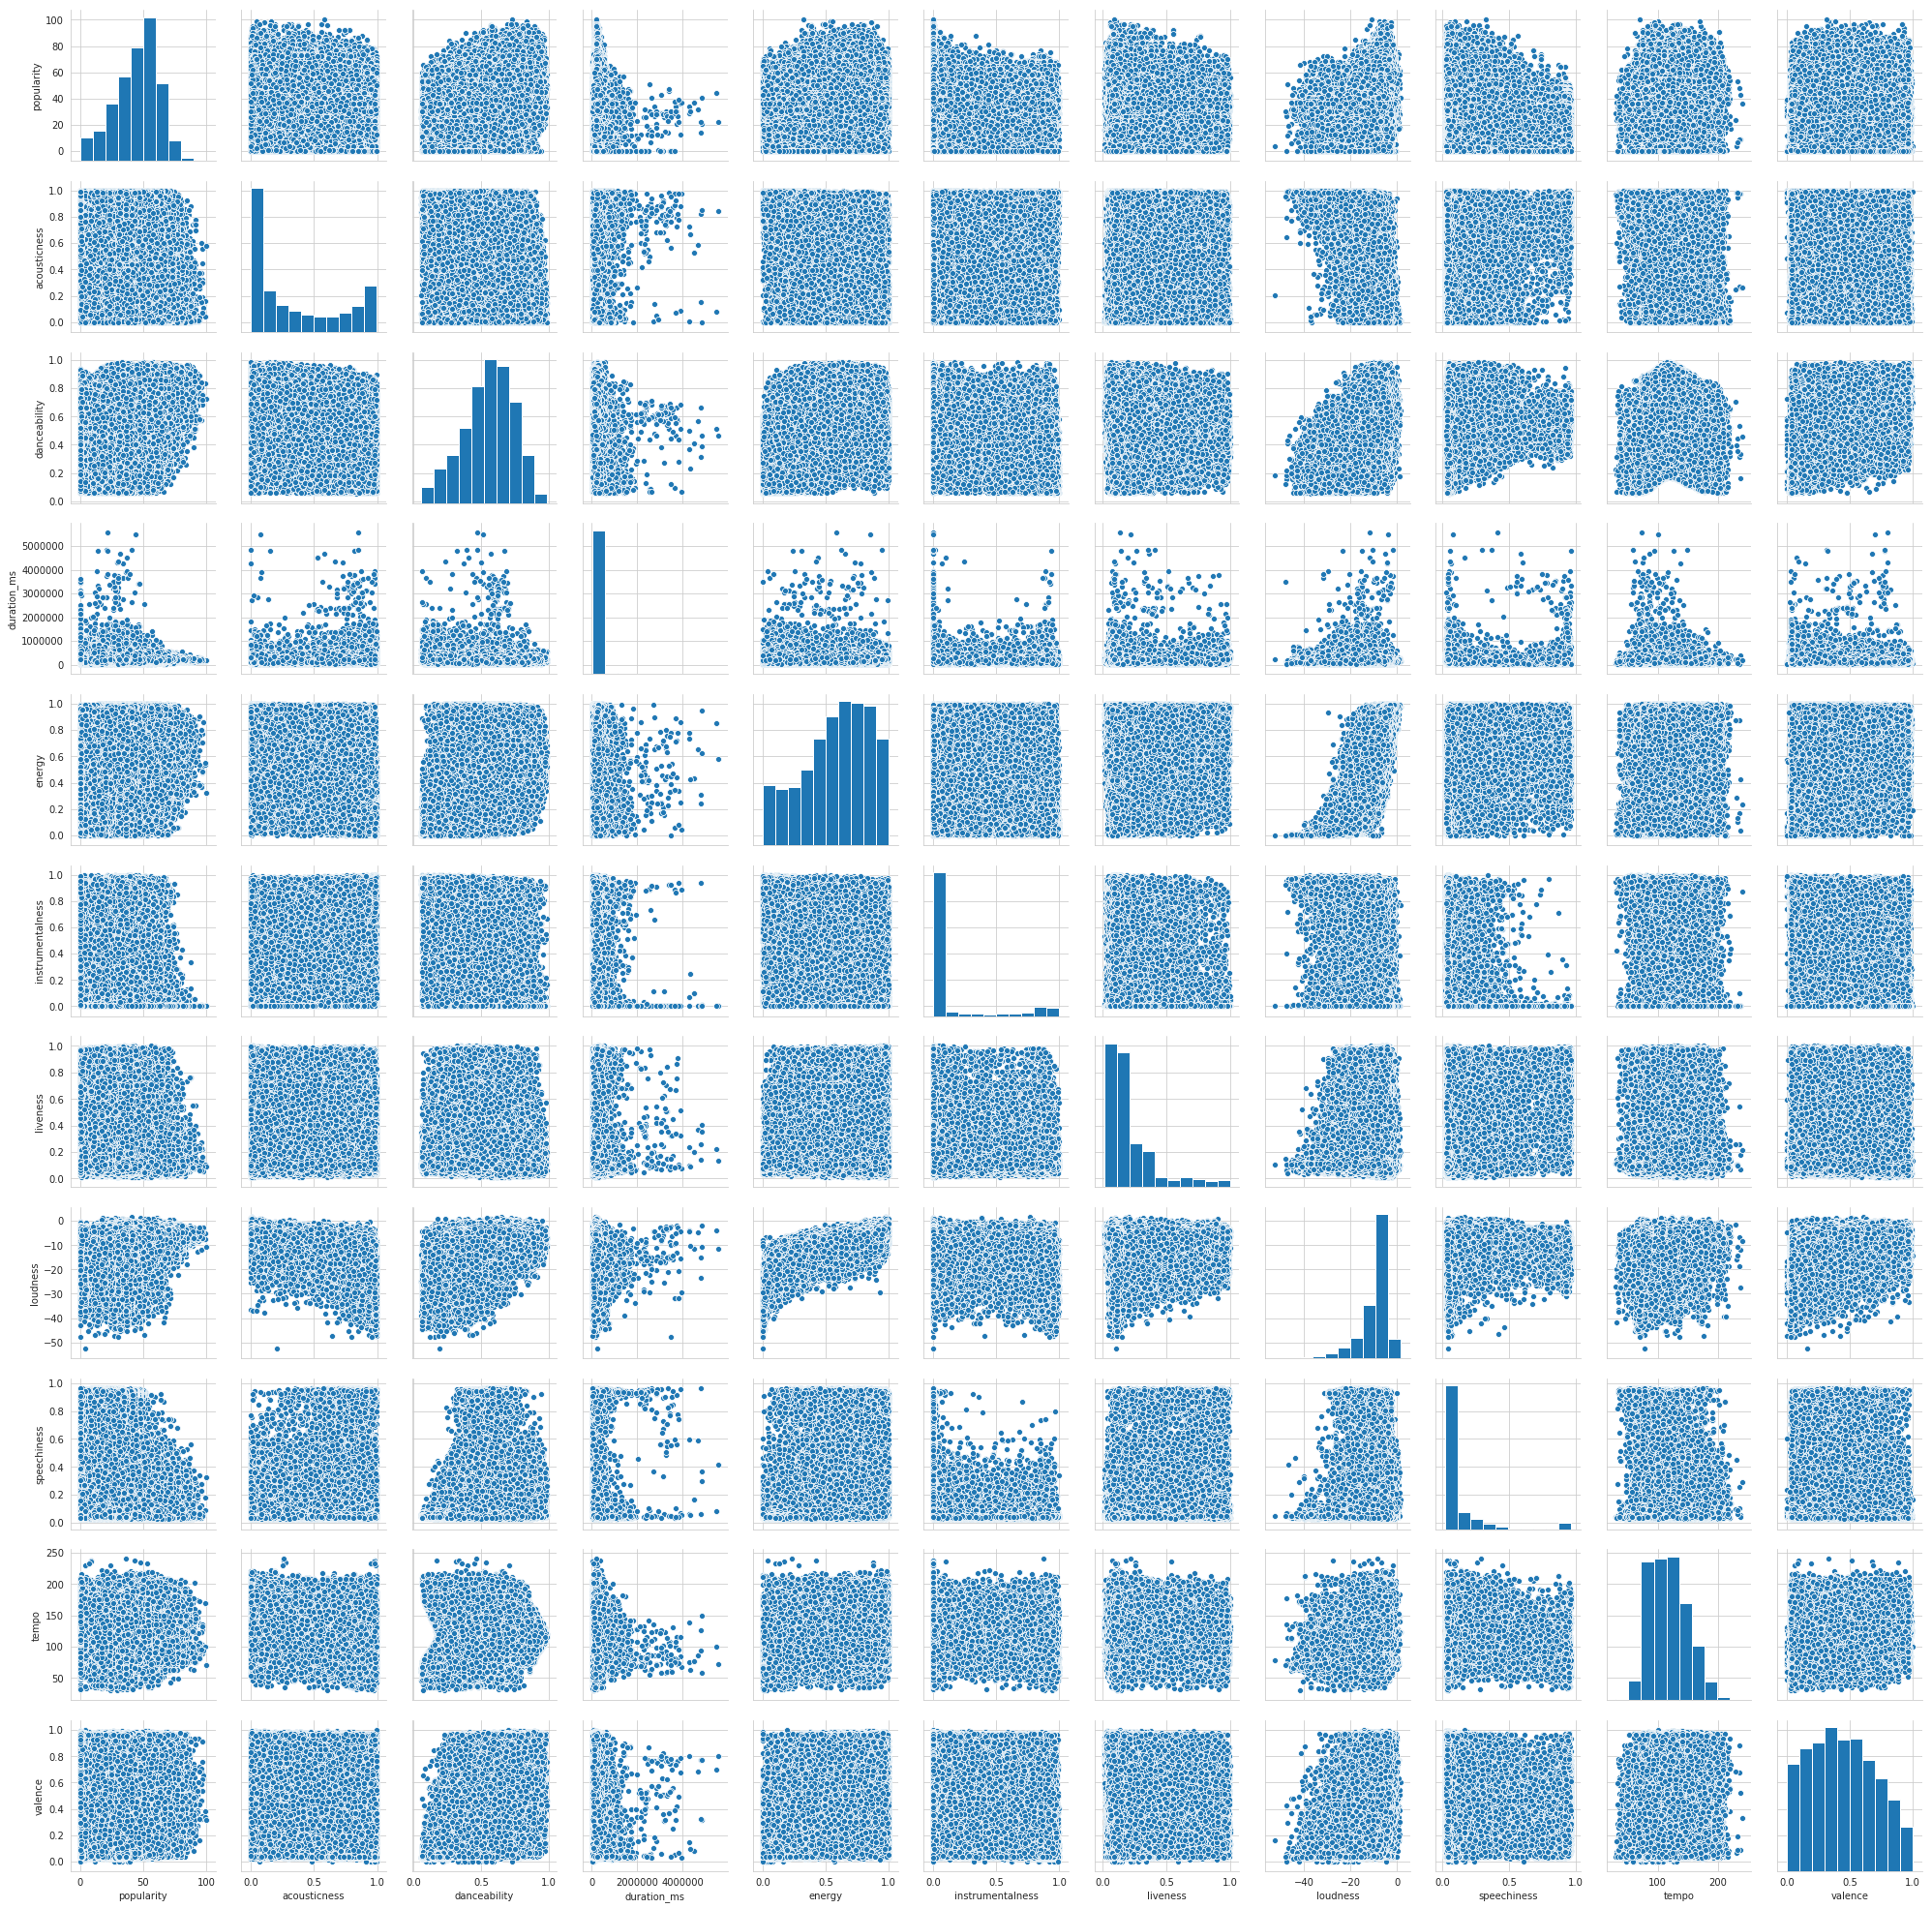

In [ ]:
 sns.pairplot(dataframe)

 **6. Feature Engineering**

There are 3 categorical variables (key, mode, and time signature) that need to be converted from text to numbers using one-hot-encoding. We also define popularity as a binary variable. For our purposes, we will define above 57 as "popular" since that's the border of the top 25% of songs and encode that as 1, and below 75 as "not popular" and encode that as 0.

**Key**: Since there are 12 letter keys (not distinguishing between major and minor), we will convert A to 0, A# to 1, and so on and so forth until B is 12.

In [ ]:
list_of_keys = dataframe['key'].unique()
for i in range(len(list_of_keys)):
    dataframe.loc[dataframe['key'] == list_of_keys[i], 'key'] = i
dataframe.sample(5)

,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
99270,Rap,DeJ Loaf,You Belong To Somebody Else,7izlgARoZsidRx23DOBhad,58,0.32500,0.790,218697,0.472,0.000006,0,0.2760,-6.999,Minor,0.0656,115.055,4/4,0.287
203702,World,Casting Crowns,At Calvary,6EfFgQ5aPRJp7oinHiRMFQ,34,0.09840,0.390,237000,0.416,0.000000,6,0.0776,-8.818,Major,0.0349,175.835,4/4,0.267
201974,World,Cesaria Evora,Ausencia,79lLkqFf3SWvmWVMmznKF9,46,0.95000,0.464,227440,0.132,0.000000,8,0.3470,-11.997,Minor,0.0450,104.792,4/4,0.458
161241,Reggaeton,Guaco,La Turbulencia (En Vivo),40Px2FM8byjQsctn1PV9ox,32,0.13100,0.778,325895,0.865,0.000000,0,0.1360,-8.836,Minor,0.0582,103.626,4/4,0.861
63778,R&B,Leven Kali,Mine,61mBC6LflXg6GsX5IamQ4I,48,0.00325,0.586,237404,0.573,0.000000,0,0.0879,-5.448,Major,0.0528,80.027,4/4,0.508


**Mode**: We will assign major = 1 and minor = 0.


In [ ]:
dataframe.loc[dataframe["mode"] == 'Major', "mode"] = 1
dataframe.loc[dataframe["mode"] == 'Minor', "mode"] = 0
dataframe.sample(5)


,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
43586,Children’s Music,Glass Animals,Poplar St,3ApAsbQP7d5GlFwwdExaTY,61,0.247000,0.575,262540,0.446,0.005670,9,0.137,-7.802,0,0.0296,68.985,4/4,0.259
90633,Children’s Music,Two Door Cinema Club,Changing of the Seasons,3KL3eFVpAVW36M9YrK2Zrk,50,0.000052,0.544,222880,0.865,0.000290,3,0.116,-4.644,1,0.1370,130.014,4/4,0.593
25786,Alternative,Cultura Profética,La complicidad,2jz6smAw1Pzy7Gs5AJACv3,65,0.134000,0.659,363920,0.746,0.000023,7,0.171,-5.636,1,0.0923,128.982,4/4,0.666
20998,Alternative,Lifehouse,Whatever It Takes,3nzL5CIQiCEt6jRt1AlQ9d,52,0.005710,0.439,207240,0.874,0.000000,2,0.176,-4.165,1,0.0299,150.036,4/4,0.527
183011,Jazz,Tal Wilkenfeld,Killing Me,0iCWgezFQGWwygQ1bQpr0l,39,0.011200,0.504,233293,0.666,0.074400,4,0.151,-8.174,1,0.0437,151.357,4/4,0.257


In [ ]:
list_of_time_signatures = dataframe['time_signature'].unique()
for i in range(len(list_of_time_signatures)):
    dataframe.loc[dataframe['time_signature'] == list_of_time_signatures[i], 'time_signature'] = i
dataframe.sample(5)

,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
104430,Reggae,Nahko and Medicine for the People,Manifesto II,0IsDvY2eXqASI0wrL8MnVq,43,0.02320,0.479,324750,0.669,0.000003,8,0.0942,-5.623,1,0.0620,119.867,0,0.480
153086,Country,Kenny Chesney,El Cerrito Place,13JngJc6J0ykO7Pq0gin35,46,0.13000,0.596,351613,0.503,0.000000,9,0.0754,-7.606,1,0.0272,134.032,0,0.262
166359,Rock,Queen,Fat Bottomed Girls - Single Version,35cljnTV9schHORuqWF8mA,61,0.06520,0.426,203280,0.697,0.000000,3,0.3220,-7.450,1,0.0620,87.708,0,0.540
91090,Children’s Music,Dibia$E,Fly Me T' The Moon,3sbGGW0bq6HgJQq8eNZhCm,51,0.01450,0.655,134014,0.580,0.000011,5,0.1130,-8.041,0,0.2920,85.828,0,0.908
134624,Reggae,Los Cafres,El Silencio,490zFllTSVutzmCeB12226,46,0.00864,0.873,223347,0.547,0.000011,11,0.0773,-8.059,0,0.0832,149.997,0,0.713


**Popularity**

In [ ]:
dataframe.loc[dataframe['popularity'] < 57, 'popularity'] = 0
dataframe.loc[dataframe['popularity'] >= 57, 'popularity'] = 1
dataframe.loc[dataframe['popularity'] == 1]


,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
242,Alternative,Joji,SLOW DANCING IN THE DARK,0rKtyWc8bvkriBthvHKY8d,1,0.544000,0.5150,209274,0.4790,0.005980,1,0.1910,-7.458,1,0.0261,88.964,0,0.2840
243,Alternative,YUNGBLUD,11 Minutes (with Halsey feat. Travis Barker),4mGdjNMo0RonTlOEb7cYg4,1,0.011600,0.4640,239507,0.8520,0.000000,6,0.1080,-3.804,1,0.0670,160.075,0,0.2330
244,Alternative,H.E.R.,Best Part (feat. Daniel Caesar),4OBZT9EnhYIV17t4pGw7ig,1,0.795000,0.4730,209400,0.3710,0.000000,9,0.1090,-10.219,0,0.0405,75.208,0,0.4130
245,Alternative,Joji,YEAH RIGHT,1VGzxJnVQND7Cg5H5wGj14,1,0.619000,0.6720,174358,0.5880,0.241000,0,0.0992,-9.573,1,0.1330,169.033,0,0.2040
246,Alternative,H.E.R.,Could've Been (feat. Bryson Tiller),6lzLjIOyWTyTJvk0jraYee,1,0.640000,0.5450,248467,0.3300,0.000007,0,0.2200,-11.719,0,0.1640,103.553,0,0.3990
247,Alternative,Joji,CAN'T GET OVER YOU (feat. Clams Casino),39oeKRgsLeynDIbWuXyA47,1,0.684000,0.9000,107077,0.3160,0.077100,7,0.0853,-8.797,1,0.3320,129.914,0,0.8440
248,Alternative,6LACK,Pretty Little Fears (feat. J. Cole),4at3d5QWnlibMVN75ECDrp,1,0.711000,0.6110,240342,0.4660,0.000264,7,0.0847,-11.361,1,0.3720,192.080,0,0.2230
249,Alternative,lovelytheband,broken,6XcfKZvJio9Z0fQy11GnNX,1,0.001750,0.6660,204878,0.7280,0.000004,8,0.0429,-5.808,1,0.0419,122.996,0,0.5100
250,Alternative,Joji,TEST DRIVE,1DMEzmAoQIikcL52psptQL,1,0.710000,0.6460,179423,0.6480,0.003160,1,0.1080,-8.602,1,0.0372,75.004,0,0.4660
251,Alternative,Smash Mouth,All Star,3cfOd4CMv2snFaKAnMdnvK,1,0.031900,0.7310,200373,0.8610,0.000000,6,0.0829,-5.881,1,0.0323,104.034,0,0.7800


**7. Model Fitting and Predicting**

We will use the same models as seen in a previous study on predicting song similarity: https://towardsdatascience.com/song-popularity-predictor-1ef69735e380. For simplicity and using binary classification, we define as the top 25% popular songs as "popular", and the bottom 75% popular songs as "not popular".  

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC, LinearSVC
from xgboost import XGBClassifier

from sklearn.metrics import make_scorer, accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split


For feature selection, we will select the following features which are only based on music theory and not artist/song information: acousticness, danceability, duration_ms, energy, instrumentalness, key, liveliness, loudness, mode, speeciness, tempo, time_signature, and valence.

In [ ]:
features = ["acousticness", "danceability", "duration_ms", "energy", "instrumentalness", "key", "liveness",
            "mode", "speechiness", "tempo", "time_signature", "valence"]

Next we define 80% of the dataframe for training and 20% of the dataframe for testing.

In [ ]:
training = dataframe.sample(frac = 0.8,random_state = 420)
X_train = training[features]
y_train = training['popularity']
X_test = dataframe.drop(training.index)[features]

We add a validation dataset using train_test_split.

In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, test_size = 0.2, random_state = 420)

**Logistic Regression**

In [ ]:
LR_Model = LogisticRegression()
LR_Model.fit(X_train, y_train)
LR_Predict = LR_Model.predict(X_valid)
LR_Accuracy = accuracy_score(y_valid, LR_Predict)
print("Accuracy: " + str(LR_Accuracy))

LR_AUC = roc_auc_score(y_valid, LR_Predict)
print("AUC: " + str(LR_AUC))

Accuracy: 0.7497945543198379
AUC: 0.5


**Random Forest Classifier**

In [ ]:
RFC_Model = RandomForestClassifier()
RFC_Model.fit(X_train, y_train)
RFC_Predict = RFC_Model.predict(X_valid)
RFC_Accuracy = accuracy_score(y_valid, RFC_Predict)
print("Accuracy: " + str(RFC_Accuracy))

RFC_AUC = roc_auc_score(y_valid, RFC_Predict)
print("AUC: " + str(RFC_AUC))

Accuracy: 0.9205336109132746
AUC: 0.8641031987700236


**K-Nearest Neighbors Classifier**

In [ ]:
KNN_Model = KNeighborsClassifier()
KNN_Model.fit(X_train, y_train)
KNN_Predict = KNN_Model.predict(X_valid)
KNN_Accuracy = accuracy_score(y_valid, KNN_Predict)
print("Accuracy: " + str(KNN_Accuracy))

KNN_AUC = roc_auc_score(y_valid, KNN_Predict)
print("AUC: " + str(KNN_AUC))

Accuracy: 0.7764750999835643
AUC: 0.6891817633896552


**Decision Tree Classifier**

In [ ]:
DT_Model = DecisionTreeClassifier()
DT_Model.fit(X_train, y_train)
DT_Predict = DT_Model.predict(X_valid)
DT_Accuracy = accuracy_score(y_valid, DT_Predict)
print("Accuracy: " + str(DT_Accuracy))

DT_AUC = roc_auc_score(y_valid, DT_Predict)
print("AUC: " + str(DT_AUC))

Accuracy: 0.8750616337040487
AUC: 0.8584364539963084


**Linear Support Vector Classification**

Since LSVC is O(n^3), and the training data set has 182,000 datapoints, it would take 10^15 operations to train the model. Therefore we will only use 10000 datapoints total.

In [ ]:
training_LSVC = training.sample(10000)
X_train_LSVC = training_LSVC[features]
y_train_LSVC = training_LSVC['popularity']
X_test_LSVC = dataframe.drop(training_LSVC.index)[features]
X_train_LSVC, X_valid_LSVC, y_train_LSVC, y_valid_LSVC = train_test_split(
    X_train_LSVC, y_train_LSVC, test_size = 0.2, random_state = 420)


In [ ]:
LSVC_Model = DecisionTreeClassifier()
LSVC_Model.fit(X_train_LSVC, y_train_LSVC)
LSVC_Predict = LSVC_Model.predict(X_valid_LSVC)
LSVC_Accuracy = accuracy_score(y_valid_LSVC, LSVC_Predict)
print("Accuracy: " + str(LSVC_Accuracy))

LSVC_AUC = roc_auc_score(y_valid_LSVC, LSVC_Predict)
print("AUC: " + str(LSVC_AUC))

Accuracy: 0.69
AUC: 0.5847764816775457


**XGBOOST**

In [ ]:
XGB_Model = XGBClassifier(objective = "binary:logistic", n_estimators = 10, seed = 123)
XGB_Model.fit(X_train, y_train)
XGB_Predict = XGB_Model.predict(X_valid)
XGB_Accuracy = accuracy_score(y_valid, XGB_Predict)
print("Accuracy: " + str(XGB_Accuracy))

XGB_AUC = roc_auc_score(y_valid, XGB_Predict)
print("AUC: " + str(XGB_AUC))

Accuracy: 0.7497945543198379
AUC: 0.5


**8. Model Performance Summary**

In [ ]:
model_performance_accuracy = pd.DataFrame({'Model': ['LogisticRegression',
                                                      'RandomForestClassifier',
                                                      'KNeighborsClassifier',
                                                      'DecisionTreeClassifier',
                                                      'LinearSVC',
                                                      'XGBClassifier'],
                                            'Accuracy': [LR_Accuracy,
                                                         RFC_Accuracy,
                                                         KNN_Accuracy,
                                                         DT_Accuracy,
                                                         LSVC_Accuracy,
                                                         XGB_Accuracy]})

model_performance_AUC = pd.DataFrame({'Model': ['LogisticRegression',
                                                      'RandomForestClassifier',
                                                      'KNeighborsClassifier',
                                                      'DecisionTreeClassifier',
                                                      'LinearSVC',
                                                      'XGBClassifier'],
                                            'AUC': [LR_AUC,
                                                         RFC_AUC,
                                                         KNN_AUC,
                                                         DT_AUC,
                                                         LSVC_AUC,
                                                         XGB_AUC]})

In [ ]:
model_performance_accuracy.sort_values(by = "Accuracy", ascending = False)

,Model,Accuracy
1,RandomForestClassifier,0.920534
3,DecisionTreeClassifier,0.875062
2,KNeighborsClassifier,0.776475
0,LogisticRegression,0.749795
5,XGBClassifier,0.749795
4,LinearSVC,0.690000


In [ ]:
model_performance_AUC.sort_values(by = "AUC", ascending = False)

,Model,AUC
1,RandomForestClassifier,0.864103
3,DecisionTreeClassifier,0.858436
2,KNeighborsClassifier,0.689182
4,LinearSVC,0.584776
0,LogisticRegression,0.500000
5,XGBClassifier,0.500000


**9. Conclusion**

Using a dataset of 228,000 Spotify Tracks, we were able to predict popularity (greater than 57 popularity) using audio-based metrics such as key, mode, and danceability without external metrics such as artist name, genre, and release date. The Random Forest Classifier was the best performing algorithm with 92.0% accuracy and 86.4% AUC. The Decision Tree Classifier was the second best performing algorithm with 87.5% accuracy and 85.8% AUC.

Moving forward, I will use a larger Spotify database by using the Spotify API to collect my own data, and explore different algorithms to predict popularity score rather than doing binary classification.

**10. References**

1. Cher Lau-Cher Lau - https://towardsdatascience.com/5-steps-of-a-data-science-project-lifecycle-26c50372b492
2. Are Hit Songs Becoming Less Musically Diverse?
Andrew Thompson-Matt Daniels-Damián Gaume - https://pudding.cool/2018/05/similarity/
3. Song Popularity Predictor
Mohamed Nasreldin-Mohamed Nasreldin - https://towardsdatascience.com/song-popularity-predictor-1ef69735e380
4. Titanic: Beginner's Guide with Sklearn
https://www.kaggle.com/ialimustafa/titanic-beginner-s-guide-with-sklearn/data
5. **Data Source:** https://www.kaggle.com/zaheenhamidani/ultimate-spotify-tracks-db#SpotifyFeatures.csv